# Лабораторная работа №2. Исследование логистической и линейной регрессии

| Задача | Датасет | Модель |
|---|---|---|
| Классификация | GTZAN — жанр по аудиопризнакам (10 классов) | логистическая регрессия |
| Регрессия | YearPredictionMSD — год выпуска песни | линейная регрессия |

Датасеты, их обоснование, разбиения train/test и метрики выбраны в ЛР1 (`lab1_knn.ipynb`, раздел 1) и не меняются, чтобы результаты всех ЛР можно было сравнивать. Основные метрики: **macro-F1** для классификации и **MAE** (в годах) для регрессии.

**План работы**
1. Кратко о моделях и данных.
2. Бейзлайн: `LogisticRegression` / `LinearRegression` из sklearn с параметрами по умолчанию.
3. Улучшение бейзлайна: гипотезы → проверка на кросс-валидации → улучшенный бейзлайн.
4. Собственная реализация логистической и линейной регрессии: сравнение с п. 2 и п. 3.
5. Итоги и сравнение с ЛР1 (KNN).

Импорты и общие настройки ноутбука

In [1]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import HuberRegressor, Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import ConfusionMatrixDisplay, log_loss
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, PowerTransformer, QuantileTransformer, SplineTransformer, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.data import RANDOM_STATE, download_data, gtzan_split, msd_split
from src.results import RESULTS_DIR, classification_metrics, regression_metrics, save_results

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
np.random.seed(RANDOM_STATE)

Загружаем данные с теми же фиксированными разбиениями, что и в ЛР1

In [2]:
download_data()
Xc_train, Xc_test, yc_train, yc_test, gc_train, gc_test = gtzan_split()
Xr_train, Xr_test, yr_train, yr_test = msd_split()
print("GTZAN train/test:", Xc_train.shape, Xc_test.shape)
print("MSD   train/test:", Xr_train.shape, Xr_test.shape)

GTZAN train/test: (7993, 57) (1997, 57)
MSD   train/test: (50000, 90) (10000, 90)


## 1. Кратко о моделях

**Логистическая регрессия (мультиклассовая, softmax).** Для каждого класса $c$ модель считает линейную оценку $z_c = w_c^\top x + b_c$ и переводит оценки в вероятности: $p_c = \dfrac{e^{z_c}}{\sum_j e^{z_j}}$. Параметры подбираются минимизацией кросс-энтропии с L2-регуляризацией. В параметризации sklearn это $\frac{1}{2}\|W\|^2 + C \sum_i -\log p_{y_i}(x_i)$, где чем меньше $C$, тем сильнее регуляризация. Аналитического решения нет, используется итеративная оптимизация (по умолчанию L-BFGS, 100 итераций). Граница между классами линейна по признакам.

**Линейная регрессия.** Прогноз $\hat y = w^\top x + b$. Метод наименьших квадратов минимизирует $\sum_i (y_i - \hat y_i)^2$ и имеет аналитическое решение $w = (X^\top X)^{-1} X^\top y$ (для центрированных данных). Ridge добавляет штраф $\alpha\|w\|^2$.

Обе модели линейны, поэтому для них особенно важны предобработка и конструирование признаков: всю нелинейность нужно «заложить» в признаки.

Нулевые модели для ориентира (как в ЛР1)

In [3]:
dummy_r = DummyRegressor().fit(Xr_train, yr_train)
pd.DataFrame({"GTZAN (most_frequent)": classification_metrics(yc_test, DummyClassifier().fit(Xc_train, yc_train).predict(Xc_test)),
              "MSD (mean)": regression_metrics(yr_test, dummy_r.predict(Xr_test))}).T

,accuracy,f1_macro,MAE,RMSE,R2
GTZAN (most_frequent),0.0651,0.0122,NaN,NaN,NaN
MSD (mean),NaN,NaN,8.1748,10.8879,-4.7542e-06


## 2. Создание бейзлайна и оценка качества

Бейзлайн — `LogisticRegression()` и `LinearRegression()` с параметрами по умолчанию на исходных признаках без предобработки.

Бейзлайн: обучаем модели «из коробки» и считаем предупреждения о несходимости оптимизатора

In [4]:
results = {"classification": {}, "regression": {}}

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    base_clf = LogisticRegression().fit(Xc_train, yc_train)
print("Предупреждений ConvergenceWarning:", sum(issubclass(w.category, ConvergenceWarning) for w in caught))
print("Итераций L-BFGS:", base_clf.n_iter_[0], "из", base_clf.max_iter)
results["classification"]["sklearn baseline"] = classification_metrics(yc_test, base_clf.predict(Xc_test))

base_reg = LinearRegression().fit(Xr_train, yr_train)
results["regression"]["sklearn baseline"] = regression_metrics(yr_test, base_reg.predict(Xr_test))
pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T

Предупреждений ConvergenceWarning: 1
Итераций L-BFGS: 100 из 100


(                  accuracy  f1_macro
 sklearn baseline    0.1768    0.1394,
                      MAE    RMSE      R2
 sklearn baseline  6.8823  9.6147  0.2202)

**Выводы по бейзлайну.**
* **Классификация:** качество низкое. Оптимизатор L-BFGS не сошёлся за 100 итераций, потому что признаки GTZAN отличаются по масштабу на 6–7 порядков (дисперсии спектральных характеристик ~10⁶, коэффициенты chroma ~10⁻¹). Задача оптимизации плохо обусловлена, и модель недообучена.
* **Регрессия:** у линейной регрессии нет итеративной оптимизации — решение находится аналитически, поэтому масштаб признаков ей не мешает. Уже бейзлайн заметно лучше константы и лучше улучшенного KNN из ЛР1: связь тембра с годом в значительной степени линейна, а KNN страдает от «проклятия размерности» на 90 признаках.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

| № | Гипотеза | Задача |
|---|---|---|
| Г1 | Стандартизация признаков улучшит сходимость логистической регрессии и качество. Для МНК она ничего не изменит: решение инвариантно к масштабу признаков | обе |
| Г2 | Преобразование тяжелохвостых признаков к нормальному виду (`QuantileTransformer`, `PowerTransformer`) уменьшит влияние выбросов на линейную модель | обе |
| Г3 | Нелинейные признаки (полиномиальные степени 2, сплайны) позволят линейной модели описывать нелинейные зависимости | обе |
| Г4 | Подбор силы регуляризации (`C` для логистической регрессии, `alpha` для Ridge/Lasso) | обе |
| Г5 | Робастная функция потерь Huber уменьшит влияние редких старых записей с большими ошибками | регрессия |
| Г6 | Логарифмическое преобразование целевой переменной `log(2012 − year)` сделает её распределение менее скошенным | регрессия |

Как и в ЛР1, гипотезы проверяются только на кросс-валидации по обучающей выборке с теми же фолдами (`GroupKFold` по трекам для GTZAN, `KFold` для MSD). Тестовая выборка используется один раз — для итоговой оценки.

Функции оценки на кросс-валидации: средний macro-F1 (GTZAN) и средний MAE (MSD) по 5 фолдам

In [5]:
cv_c = GroupKFold(n_splits=5)
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def cv_clf(model):
    return cross_val_score(model, Xc_train, yc_train, cv=cv_c, groups=gc_train, scoring="f1_macro", n_jobs=5).mean()

def cv_reg(model, X=Xr_train):
    return -cross_val_score(model, X, yr_train, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=5).mean()

QT = lambda: QuantileTransformer(output_distribution="normal", random_state=RANDOM_STATE)
hyp_c = {"бейзлайн": cv_clf(LogisticRegression())}
hyp_r = {"бейзлайн": cv_reg(LinearRegression())}

#### Г1. Стандартизация признаков

Логистическая регрессия на стандартизированных признаках (max_iter увеличен, чтобы оптимизатор гарантированно сошёлся) и МНК после стандартизации

In [6]:
hyp_c["Г1: StandardScaler"] = cv_clf(Pipeline([("prep", StandardScaler()), ("lr", LogisticRegression(max_iter=3000))]))
hyp_r["Г1: StandardScaler"] = cv_reg(Pipeline([("prep", StandardScaler()), ("lr", LinearRegression())]))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.1842,6.7843
Г1: StandardScaler,0.6622,6.7843


**Г1 подтверждена для классификации:** после стандартизации оптимизатор сходится, и macro-F1 вырастает более чем в 3 раза. **Для регрессии Г1, как и ожидалось, ничего не меняет:** решение МНК при линейной замене признаков меняет только коэффициенты, а прогнозы остаются теми же. Стандартизация станет важна для регрессии при регуляризации (штраф зависит от масштаба коэффициентов) и при обучении градиентным спуском — это видно в п. 4.

#### Г2. Преобразование распределений признаков

QuantileTransformer и PowerTransformer вместо StandardScaler

In [7]:
for name, prep in [("PowerTransformer", PowerTransformer()), ("QuantileTransformer", QT())]:
    hyp_c[f"Г2: {name}"] = cv_clf(Pipeline([("prep", prep), ("lr", LogisticRegression(max_iter=3000))]))
    hyp_r[f"Г2: {name}"] = cv_reg(Pipeline([("prep", clone(prep)), ("lr", LinearRegression())]))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.1842,6.7843
Г1: StandardScaler,0.6622,6.7843
Г2: PowerTransformer,0.6670,6.7305
Г2: QuantileTransformer,0.6747,6.6854


**Г2 подтверждена для обеих задач.** Лучше всего работает `QuantileTransformer`: он приводит каждый признак к нормальному распределению, «сжимает» выбросы и делает зависимости ближе к линейным. Для линейной регрессии это уже не просто масштабирование, а нелинейное преобразование признаков, поэтому MAE снижается. Дальше используем `QuantileTransformer`.

#### Г3. Нелинейные признаки: полиномы степени 2 и сплайны

Полиномиальные признаки (все попарные произведения и квадраты) и сплайны (кусочно-полиномиальные функции каждого признака)

In [8]:
hyp_c["Г3: Quantile + Poly(2)"] = cv_clf(Pipeline([("prep", QT()), ("feat", PolynomialFeatures(2)), ("sc", StandardScaler()),
                                                   ("lr", LogisticRegression(C=0.01, max_iter=3000))]))
hyp_c["Г3: Quantile + Spline"] = cv_clf(Pipeline([("prep", QT()), ("feat", SplineTransformer(n_knots=5)),
                                                  ("lr", LogisticRegression(C=0.1, max_iter=3000))]))
hyp_r["Г3: Scaler + Poly(2) + Ridge"] = cv_reg(Pipeline([("prep", StandardScaler()), ("feat", PolynomialFeatures(2)), ("sc", StandardScaler()),
                                                         ("lr", Ridge(1000))]))
hyp_r["Г3: Quantile + Spline"] = cv_reg(Pipeline([("prep", QT()), ("feat", SplineTransformer(n_knots=5)), ("lr", Ridge(10))]))
print("Число признаков: Poly(2) GTZAN =", PolynomialFeatures(2).fit(Xc_train).n_output_features_,
      "| Poly(2) MSD =", PolynomialFeatures(2).fit(Xr_train).n_output_features_,
      "| Spline MSD =", SplineTransformer(n_knots=5).fit(Xr_train).n_features_out_)
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

Число признаков: Poly(2) GTZAN = 1711 | Poly(2) MSD = 4186 | Spline MSD = 630


,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.1842,6.7843
Г1: StandardScaler,0.6622,6.7843
Г2: PowerTransformer,0.6670,6.7305
Г2: QuantileTransformer,0.6747,6.6854
Г3: Quantile + Poly(2),0.7098,NaN
Г3: Quantile + Spline,0.6816,6.5373
Г3: Scaler + Poly(2) + Ridge,NaN,6.8077


**Г3 подтверждена частично.**
* Для **GTZAN** полиномиальные признаки дают заметный прирост: произведения пар признаков (например, громкость × «яркость» спектра) позволяют разделять жанры нелинейными границами. Регуляризация здесь обязательна, иначе 1 711 признаков на ~8 000 объектов приводят к переобучению; значения `C` взяты предварительные и подбираются в Г4. Сплайны дают меньший прирост.
* Для **MSD** полиномы на всех 90 признаках (4 186 признаков) не помогают, а сплайны снижают MAE: они моделируют нелинейную зависимость года от каждого признака по отдельности, не раздувая число параметров.

#### Г4. Сила регуляризации

Ridge и Lasso для МНК на квантильно преобразованных признаках: перебираем alpha

In [9]:
alphas = [0.01, 1, 100, 1000, 10000]
ridge_curve = {a: cv_reg(Pipeline([("prep", QT()), ("lr", Ridge(alpha=a))])) for a in alphas}
lasso_curve = {a: cv_reg(Pipeline([("prep", QT()), ("lr", Lasso(alpha=a / 10000, max_iter=5000))])) for a in alphas}
pd.DataFrame({"Ridge alpha": alphas, "Ridge MAE": ridge_curve.values(),
              "Lasso alpha": [a / 10000 for a in alphas], "Lasso MAE": lasso_curve.values()})

,Ridge alpha,Ridge MAE,Lasso alpha,Lasso MAE
0,0.01,6.6854,1.0000e-06,6.6854
1,1.00,6.6854,1.0000e-04,6.6854
2,100.00,6.6852,1.0000e-02,6.6800
3,1000.00,6.6913,1.0000e-01,6.7047
4,10000.00,6.8646,1.0000e+00,7.5458


Для MSD регуляризация линейной модели почти не влияет на качество: объектов (40 000 в каждом фолде) на порядки больше, чем признаков (90), так что переобучаться модели не на чем. Сильная регуляризация лишь ухудшает результат. Регуляризация нужна там, где признаков много: в логистической регрессии с полиномиальными признаками и в регрессии на сплайнах. Её подбор выполняется вместе с остальными гиперпараметрами в п. 3.2.

#### Г5. Робастная функция потерь Huber

HuberRegressor: квадратичные потери для малых остатков и линейные для больших (epsilon — порог в единицах масштаба остатков)

In [10]:
for eps in [1.1, 1.35, 2.0]:
    hyp_r[f"Г5: Quantile + Huber(eps={eps})"] = cv_reg(Pipeline([("prep", QT()), ("lr", HuberRegressor(epsilon=eps, max_iter=1000))]))
pd.Series(hyp_r, name="MSD MAE ↓").to_frame()

,MSD MAE ↓
бейзлайн,6.7843
Г1: StandardScaler,6.7843
Г2: PowerTransformer,6.7305
Г2: QuantileTransformer,6.6854
Г3: Scaler + Poly(2) + Ridge,6.8077
Г3: Quantile + Spline,6.5373
Г5: Quantile + Huber(eps=1.1),6.4038
Г5: Quantile + Huber(eps=1.35),6.4089
Г5: Quantile + Huber(eps=2.0),6.4899


**Г5 подтверждена.** Huber снижает MAE относительно МНК на тех же признаках. МНК минимизирует квадраты ошибок, поэтому редкие очень старые записи (1920–1960-е), на которых модель ошибается на десятки лет, сильно «тянут» коэффициенты. Huber учитывает большие ошибки линейно, и модель лучше подстраивается под основную массу песен, что и уменьшает MAE.

#### Г6. Логарифмическое преобразование целевой переменной

Распределение года и log(2012 - year): после преобразования длинный левый хвост становится короче

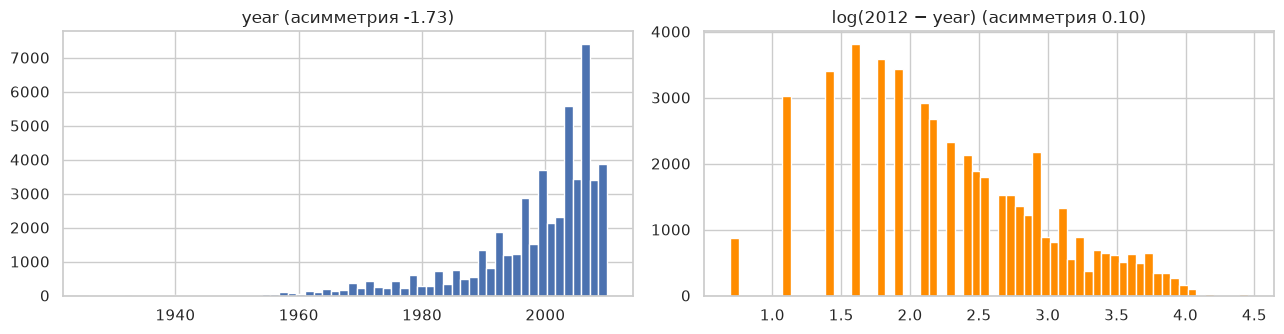

In [11]:
log_y = lambda y: np.log(2012 - y)
exp_y = lambda z: 2012 - np.exp(z)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(yr_train, bins=60); axes[0].set_title(f"year (асимметрия {pd.Series(yr_train).skew():.2f})")
axes[1].hist(log_y(yr_train), bins=60, color="darkorange"); axes[1].set_title(f"log(2012 − year) (асимметрия {pd.Series(log_y(yr_train)).skew():.2f})")
plt.tight_layout(); plt.show()

Модель учится предсказывать log(2012 - year), прогноз переводится обратно в год (TransformedTargetRegressor)

In [12]:
def log_target(model):
    return TransformedTargetRegressor(regressor=model, func=log_y, inverse_func=exp_y)

hyp_r["Г6: Quantile + OLS + log-таргет"] = cv_reg(log_target(Pipeline([("prep", QT()), ("lr", LinearRegression())])))
hyp_r["Г6: Quantile + Spline + log-таргет"] = cv_reg(log_target(Pipeline([("prep", QT()), ("feat", SplineTransformer(n_knots=5)), ("lr", Ridge(10))])))
hyp_r["Г5+Г6: Quantile + Huber + log-таргет"] = cv_reg(log_target(Pipeline([("prep", QT()), ("lr", HuberRegressor(max_iter=1000))])))
pd.Series(hyp_r, name="MSD MAE ↓").to_frame()

,MSD MAE ↓
бейзлайн,6.7843
Г1: StandardScaler,6.7843
Г2: PowerTransformer,6.7305
Г2: QuantileTransformer,6.6854
Г3: Scaler + Poly(2) + Ridge,6.8077
Г3: Quantile + Spline,6.5373
Г5: Quantile + Huber(eps=1.1),6.4038
Г5: Quantile + Huber(eps=1.35),6.4089
Г5: Quantile + Huber(eps=2.0),6.4899
Г6: Quantile + OLS + log-таргет,6.4367


**Г6 подтверждена.** Логарифм расстояния до 2012 года «растягивает» плотную область недавних лет и «сжимает» длинный хвост старых записей. Ошибки модели в новых координатах становятся более однородными, а МНК в них решает задачу, близкую к минимизации относительной ошибки. В сочетании со сплайнами получается лучший результат.

Huber поверх логарифмированного таргета уже не даёт выигрыша: обе техники решают одну проблему — влияние длинного хвоста старых записей. В улучшенный бейзлайн входит более простой и быстрый вариант: МНК (Ridge) со сплайнами на логарифмированном таргете.

### 3.2. Подбор гиперпараметров и улучшенный бейзлайн

Перебираем по сетке на кросс-валидации:
* **классификация:** предобработка (StandardScaler / QuantileTransformer), полиномиальные признаки (нет / степень 2) и сила регуляризации `C`;
* **регрессия:** число узлов сплайна `n_knots` и `alpha` в Ridge для конвейера QuantileTransformer → SplineTransformer → Ridge на логарифмированном таргете.

Сетка для логистической регрессии (GroupKFold по трекам, macro-F1)

In [13]:
pipe_c = Pipeline([("prep", StandardScaler()), ("feat", "passthrough"), ("sc", StandardScaler()),
                   ("lr", LogisticRegression(max_iter=5000))])
grid_c = GridSearchCV(pipe_c, {
    "prep": [StandardScaler(), QT()],
    "feat": ["passthrough", PolynomialFeatures(2)],
    "lr__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3],
}, cv=cv_c, scoring="f1_macro", n_jobs=6)
t0 = time.time(); grid_c.fit(Xc_train, yc_train, groups=gc_train)
print(f"{time.time() - t0:.0f} c | лучшие параметры: {grid_c.best_params_} | CV macro-F1 = {grid_c.best_score_:.4f}")
hyp_c["GridSearchCV"] = grid_c.best_score_

156 c | лучшие параметры: {'feat': PolynomialFeatures(), 'lr__C': 0.003, 'prep': QuantileTransformer(output_distribution='normal', random_state=42)} | CV macro-F1 = 0.7129


Сетка для линейной регрессии (KFold, MAE)

In [14]:
pipe_r = log_target(Pipeline([("prep", QT()), ("feat", SplineTransformer()), ("lr", Ridge())]))
grid_r = GridSearchCV(pipe_r, {
    "regressor__feat__n_knots": [3, 5, 8, 12],
    "regressor__lr__alpha": [0.1, 1, 10, 30, 100],
}, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=6)
t0 = time.time(); grid_r.fit(Xr_train, yr_train)
print(f"{time.time() - t0:.0f} c | лучшие параметры: {grid_r.best_params_} | CV MAE = {-grid_r.best_score_:.4f}")
hyp_r["GridSearchCV"] = -grid_r.best_score_

49 c | лучшие параметры: {'regressor__feat__n_knots': 8, 'regressor__lr__alpha': 10} | CV MAE = 6.2185


Зависимость качества от силы регуляризации C для логистической регрессии (лучшая предобработка)

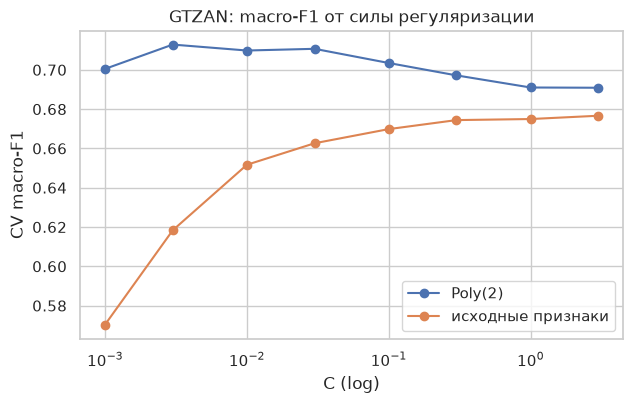

In [15]:
cvres = pd.DataFrame(grid_c.cv_results_)
cvres = cvres[cvres["param_prep"].astype(str) == str(grid_c.best_params_["prep"])]
plt.figure(figsize=(7, 4))
for feat, part in cvres.groupby(cvres["param_feat"].astype(str)):
    plt.plot(part["param_lr__C"], part["mean_test_score"], marker="o", label="Poly(2)" if "Poly" in feat else "исходные признаки")
plt.xscale("log"); plt.xlabel("C (log)"); plt.ylabel("CV macro-F1"); plt.title("GTZAN: macro-F1 от силы регуляризации"); plt.legend()
plt.show()

На графике видно, что поведение противоположное. Для исходных 57 признаков сильная регуляризация вредит (модель недообучается), и качество растёт с увеличением `C` до плато. Для полиномиальных признаков оптимум — сильная регуляризация (`C` ≈ 0.003): при слабой модель с ~17 000 параметров (1 711 признаков × 10 классов) начинает переобучаться. При этом полиномиальная модель лучше исходной при любом `C`.

Сводка проверки всех гипотез на кросс-валидации

In [16]:
pd.concat([pd.Series(hyp_c, name="GTZAN CV macro-F1 ↑"), pd.Series(hyp_r, name="MSD CV MAE ↓")], axis=1)

,GTZAN CV macro-F1 ↑,MSD CV MAE ↓
бейзлайн,0.1842,6.7843
Г1: StandardScaler,0.6622,6.7843
Г2: PowerTransformer,0.6670,6.7305
Г2: QuantileTransformer,0.6747,6.6854
Г3: Quantile + Poly(2),0.7098,NaN
Г3: Quantile + Spline,0.6816,6.5373
GridSearchCV,0.7129,6.2185
Г3: Scaler + Poly(2) + Ridge,NaN,6.8077
Г5: Quantile + Huber(eps=1.1),NaN,6.4038
Г5: Quantile + Huber(eps=1.35),NaN,6.4089


Улучшенный бейзлайн: лучшие конвейеры из GridSearchCV (уже переобучены на всём train), оценка на test

In [17]:
best_clf, best_reg = grid_c.best_estimator_, grid_r.best_estimator_
yc_pred_best, yr_pred_best = best_clf.predict(Xc_test), best_reg.predict(Xr_test)
results["classification"]["sklearn improved"] = classification_metrics(yc_test, yc_pred_best)
results["regression"]["sklearn improved"] = regression_metrics(yr_test, yr_pred_best)
pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T

(                  accuracy  f1_macro
 sklearn baseline    0.1768    0.1394
 sklearn improved    0.6790    0.6763,
                      MAE    RMSE      R2
 sklearn baseline  6.8823  9.6147  0.2202
 sklearn improved  6.3337  9.6997  0.2064)

Матрица ошибок улучшенного классификатора и сравнение «прогноз vs факт» для бейзлайна и улучшенной регрессии

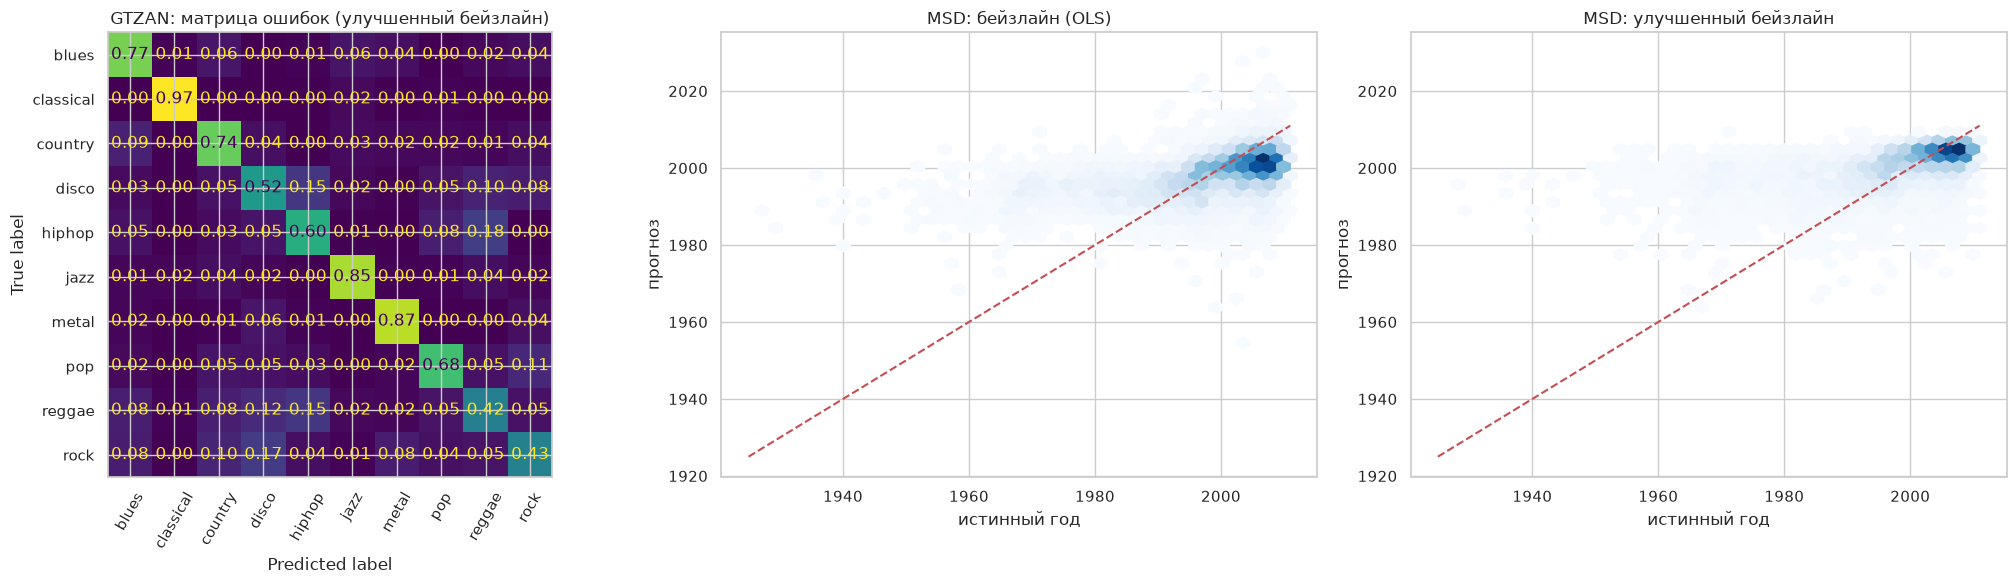

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_best, normalize="true", values_format=".2f",
                                        ax=axes[0], colorbar=False, xticks_rotation=60)
axes[0].set_title("GTZAN: матрица ошибок (улучшенный бейзлайн)")
for ax, pred, title in [(axes[1], base_reg.predict(Xr_test), "MSD: бейзлайн (OLS)"), (axes[2], yr_pred_best, "MSD: улучшенный бейзлайн")]:
    ax.hexbin(yr_test, pred, gridsize=40, cmap="Blues", mincnt=1, extent=(1925, 2011, 1925, 2030))
    ax.plot([1925, 2011], [1925, 2011], "r--"); ax.set_xlabel("истинный год"); ax.set_ylabel("прогноз"); ax.set_title(title)
plt.tight_layout(); plt.show()

**Выводы по улучшенному бейзлайну (сравнение с п. 2).**
* **Классификация:** macro-F1 вырос почти в 5 раз относительно бейзлайна. Главное — стандартизация, без которой оптимизатор не сходится. Дополнительный прирост дают квантильное преобразование и полиномиальные признаки с сильной регуляризацией. На тесте прирост от полиномов оказался меньше, чем на кросс-валидации (0.676 против 0.713 на CV). Тест содержит всего 200 треков, поэтому погрешность оценки на нём — несколько п.п. Матрица ошибок похожа на KNN: лучше всего распознаются classical, metal и jazz, хуже всего — rock, reggae и disco.
* **Регрессия:** MAE (основная метрика) снизился за счёт квантильного преобразования признаков, сплайнов и логарифмирования таргета. Но RMSE и R² немного ухудшились — это цена логарифмирования таргета. На графиках видно, что улучшенная модель гораздо точнее на основной массе песен 1995–2010 годов: плотное облако точек легло на диагональ. Зато старые записи она «сжимает» к 1980–2000 годам ещё сильнее, чем бейзлайн, и на них ошибается больше. Обе модели сильно занижают разброс прогнозов: у бейзлайна стандартное отклонение прогноза около 5.5 лет при реальном ~11. Выбор между вариантами зависит от задачи: для типичной песни лучше улучшенная модель, если же важны грубые промахи на старых записях — бейзлайн.

## 4. Имплементация алгоритмов

### 4.1. Собственная реализация

**Линейная регрессия** `MyLinearRegression`:
* `solver="normal"` — аналитическое решение. Данные центрируются, чтобы свободный член не штрафовался (как в sklearn Ridge), затем решается задача наименьших квадратов для расширенной системы $\begin{bmatrix} X \\ \sqrt{\alpha} I \end{bmatrix} w \approx \begin{bmatrix} y \\ 0 \end{bmatrix}$ через `np.linalg.lstsq` (SVD). Это эквивалентно Ridge $(X^\top X + \alpha I)^{-1} X^\top y$, но численно устойчивее явного обращения $X^\top X$.
* `solver="gd"` — градиентный спуск по функции потерь $\frac{1}{2n}\left(\|y - Xw\|^2 + \alpha\|w\|^2\right)$ с шагом $1/L$, где $L = (\lambda_{\max}(X^\top X) + \alpha)/n$ — константа Липшица градиента. $\lambda_{\max}$ оценивается степенным методом.

**Логистическая регрессия** `MyLogisticRegression` (мультиклассовая, softmax):
* минимизирует $\frac{1}{n}\sum_i -\log p_{y_i}(x_i) + \frac{1}{2Cn}\|W\|^2$ — та же задача, что и в sklearn (поделённая на $Cn$), свободный член не штрафуется;
* градиент: $\nabla_W = \frac{1}{n} X^\top (P - Y) + \frac{W}{Cn}$, где $P$ — матрица вероятностей, $Y$ — one-hot метки;
* оптимизатор — ускоренный градиентный спуск Нестерова с шагом $1/L$, $L = \frac{1}{2}\lambda_{\max}(\tilde X^\top \tilde X)/n + \frac{1}{Cn}$ ($\tilde X$ — признаки со столбцом единиц). Оценка $\frac{1}{2}$ — верхняя граница собственных чисел гессиана softmax по логитам;
* остановка по норме градиента (`tol`) или по `max_iter`.

Реализация: функция `max_eigenvalue` (степенной метод для оценки константы Липшица) и классы `MyLinearRegression` и `MyLogisticRegression`.

Детали реализации:
* в `MyLinearRegression` свободный член не входит в оптимизацию: он восстанавливается из средних, $b = \bar y - \bar x^\top w$;
* в `MyLogisticRegression` свободный член — последняя строка матрицы весов $W$ (столбец единиц в $\tilde X$), он исключается из штрафа;
* в softmax из логитов вычитается максимум по строке, чтобы `np.exp` не переполнялся;
* метод Нестерова: градиентный шаг делается из «заглядывающей вперёд» точки $V$, затем $V = W_{t+1} + \frac{t_k - 1}{t_{k+1}}(W_{t+1} - W_t)$; это ускоряет сходимость с $O(1/k)$ до $O(1/k^2)$;
* `loss_history_` сохраняет значение функции потерь на каждой итерации для графиков сходимости.

In [19]:
def max_eigenvalue(X, n_iter=100, seed=0):
    """Наибольшее собственное число X^T X степенным методом."""
    v = np.random.default_rng(seed).normal(size=X.shape[1])
    for _ in range(n_iter):
        v = X.T @ (X @ v)
        v /= np.linalg.norm(v)
    return float(v @ (X.T @ (X @ v)))


class MyLinearRegression:
    def __init__(self, alpha=0.0, solver="normal", max_iter=1000):
        assert solver in ("normal", "gd")
        self.alpha, self.solver, self.max_iter = alpha, solver, max_iter

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=np.float64), np.asarray(y, dtype=np.float64)
        x_mean, y_mean = X.mean(axis=0), y.mean()
        Xc, yc = X - x_mean, y - y_mean
        if self.solver == "normal":
            if self.alpha > 0:
                Xc = np.vstack([Xc, np.sqrt(self.alpha) * np.eye(X.shape[1])])
                yc = np.concatenate([yc, np.zeros(X.shape[1])])
            self.coef_ = np.linalg.lstsq(Xc, yc, rcond=None)[0]
        else:
            n = len(X)
            step = n / (max_eigenvalue(Xc) + self.alpha)
            w = np.zeros(X.shape[1])
            self.loss_history_ = []
            for _ in range(self.max_iter):
                residual = Xc @ w - yc
                w -= step * (Xc.T @ residual + self.alpha * w) / n
                self.loss_history_.append(0.5 * (residual @ residual) / n)
            self.coef_ = w
        self.intercept_ = y_mean - x_mean @ self.coef_
        return self

    def predict(self, X):
        return np.asarray(X, dtype=np.float64) @ self.coef_ + self.intercept_


class MyLogisticRegression:
    def __init__(self, C=1.0, max_iter=1000, tol=1e-5):
        self.C, self.max_iter, self.tol = C, max_iter, tol

    @staticmethod
    def _softmax(Z):
        Z = Z - Z.max(axis=1, keepdims=True)
        E = np.exp(Z)
        return E / E.sum(axis=1, keepdims=True)

    def _loss_grad(self, W, X1, Y):
        n = len(X1)
        P = self._softmax(X1 @ W)
        reg = W.copy(); reg[-1] = 0
        loss = -np.log(P[Y.astype(bool)].clip(1e-300)).mean() + (reg ** 2).sum() / (2 * self.C * n)
        grad = X1.T @ (P - Y) / n + reg / (self.C * n)
        return loss, grad

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        self.classes_, codes = np.unique(y, return_inverse=True)
        n, k = len(X), len(self.classes_)
        X1 = np.hstack([X, np.ones((n, 1))])
        Y = np.eye(k)[codes]
        step = 1.0 / (0.5 * max_eigenvalue(X1) / n + 1.0 / (self.C * n))
        W = np.zeros((X1.shape[1], k))
        V, t = W.copy(), 1.0
        self.loss_history_ = []
        for self.n_iter_ in range(1, self.max_iter + 1):
            loss, grad = self._loss_grad(V, X1, Y)
            W_next = V - step * grad
            t_next = (1 + np.sqrt(1 + 4 * t ** 2)) / 2
            V = W_next + (t - 1) / t_next * (W_next - W)
            W, t = W_next, t_next
            self.loss_history_.append(loss)
            if np.linalg.norm(grad) < self.tol:
                break
        self.coef_, self.intercept_ = W[:-1].T, W[-1]
        return self

    def predict_proba(self, X):
        return self._softmax(np.asarray(X, dtype=np.float64) @ self.coef_.T + self.intercept_)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

Проверка корректности: сравниваем с sklearn на стандартизированных данных (коэффициенты, прогнозы, значение функции потерь)

In [20]:
sc_r = StandardScaler().fit(Xr_train)
Ar, Br = sc_r.transform(Xr_train), sc_r.transform(Xr_test)
for alpha in [0, 100]:
    sk = (LinearRegression() if alpha == 0 else Ridge(alpha)).fit(Ar, yr_train)
    my = MyLinearRegression(alpha=alpha).fit(Ar, yr_train)
    print(f"Linear alpha={alpha:>3}: макс. разница коэффициентов {np.abs(sk.coef_ - my.coef_).max():.1e}, "
          f"прогнозов {np.abs(sk.predict(Br) - my.predict(Br)).max():.1e}")

sc_c = StandardScaler().fit(Xc_train)
Ac, Bc = sc_c.transform(Xc_train), sc_c.transform(Xc_test)
sk_log = LogisticRegression(C=1.0, max_iter=5000, tol=1e-8).fit(Ac, yc_train)
my_log = MyLogisticRegression(C=1.0, max_iter=5000, tol=1e-6).fit(Ac, yc_train)
print(f"Logistic C=1: итераций {my_log.n_iter_}, совпадение классов {(sk_log.predict(Bc) == my_log.predict(Bc)).mean():.4f}, "
      f"макс. разница вероятностей {np.abs(sk_log.predict_proba(Bc) - my_log.predict_proba(Bc)).max():.1e}")
print(f"log-loss на train: sklearn {log_loss(yc_train, sk_log.predict_proba(Ac)):.6f}, моя {log_loss(yc_train, my_log.predict_proba(Ac)):.6f}")

Linear alpha=  0: макс. разница коэффициентов 7.7e-06, прогнозов 2.3e-04


Linear alpha=100: макс. разница коэффициентов 1.0e-05, прогнозов 1.6e-04


Logistic C=1: итераций 5000, совпадение классов 0.9990, макс. разница вероятностей 3.2e-03
log-loss на train: sklearn 0.717013, моя 0.717008


Аналитическое решение совпадает с sklearn: прогнозы расходятся не более чем на 10⁻⁴ года, это уровень ошибок округления. Логистическая регрессия сходится к тому же минимуму, что и L-BFGS в sklearn: log-loss совпадает до 5-го знака, классы — в 99.9 % случаев, задача выпуклая, поэтому минимум единственный, и разные оптимизаторы приходят к одной точке.

Теперь посмотрим, как градиентный спуск ведёт себя на исходных и на стандартизированных признаках. Это нюанс Г1: для аналитического решения масштаб не важен, а для итеративной оптимизации — критичен.

Градиентный спуск для линейной регрессии: сырые признаки vs стандартизированные (1000 итераций)

Число обусловленности X^T X: сырые 1.3e+06, стандартизированные 1.8e+02


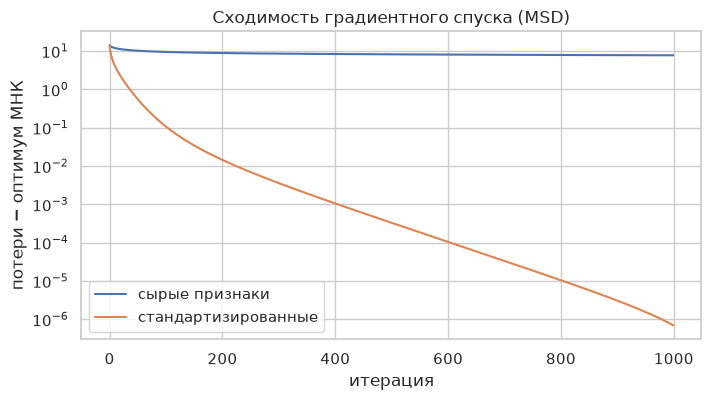

MAE на test: GD сырые = 7.6568 | GD стандартизир. = 6.8823 | аналитическое = 6.8823


In [21]:
ols_loss = 0.5 * np.mean((LinearRegression().fit(Ar, yr_train).predict(Ar) - yr_train) ** 2)
gd_raw = MyLinearRegression(solver="gd", max_iter=1000).fit(Xr_train, yr_train)
gd_sc = MyLinearRegression(solver="gd", max_iter=1000).fit(Ar, yr_train)
cond = lambda X: np.linalg.cond(X - X.mean(axis=0)) ** 2
print(f"Число обусловленности X^T X: сырые {cond(Xr_train.to_numpy()):.1e}, стандартизированные {cond(Ar):.1e}")
plt.figure(figsize=(8, 4))
plt.plot(np.array(gd_raw.loss_history_) - ols_loss, label="сырые признаки")
plt.plot(np.array(gd_sc.loss_history_) - ols_loss, label="стандартизированные")
plt.yscale("log"); plt.xlabel("итерация"); plt.ylabel("потери − оптимум МНК"); plt.title("Сходимость градиентного спуска (MSD)"); plt.legend()
plt.show()
print("MAE на test: GD сырые =", round(regression_metrics(yr_test, gd_raw.predict(Xr_test))["MAE"], 4),
      "| GD стандартизир. =", round(regression_metrics(yr_test, gd_sc.predict(Br))["MAE"], 4),
      "| аналитическое =", round(results["regression"]["sklearn baseline"]["MAE"], 4))

На сырых признаках матрица $X^\top X$ обусловлена на много порядков хуже. Шаг градиентного спуска ограничен самым «крутым» направлением ($1/L$), поэтому по пологим направлениям, соответствующим признакам малого масштаба, модель почти не двигается: за 1000 итераций спуск не приближается к оптимуму. На стандартизированных признаках он быстро сходится к решению МНК. Это та же причина, по которой не сходится `LogisticRegression` в бейзлайне.

### 4.2. Собственная реализация в условиях бейзлайна (сравнение с п. 2)

Те же условия, что в п. 2: сырые признаки, параметры по умолчанию (C=1; для регрессии — МНК без регуляризации)

In [22]:
t0 = time.time()
my_base_clf = MyLogisticRegression(C=1.0, max_iter=1000).fit(Xc_train, yc_train)
results["classification"]["custom baseline"] = classification_metrics(yc_test, my_base_clf.predict(Xc_test))
t1 = time.time()
my_base_reg = MyLinearRegression().fit(Xr_train, yr_train)
results["regression"]["custom baseline"] = regression_metrics(yr_test, my_base_reg.predict(Xr_test))
print(f"Время: классификация {t1 - t0:.1f} c ({my_base_clf.n_iter_} итераций), регрессия {time.time() - t1:.2f} c")
cmp = ["sklearn baseline", "custom baseline"]
pd.DataFrame(results["classification"]).T.loc[cmp], pd.DataFrame(results["regression"]).T.loc[cmp]

Время: классификация 4.6 c (1000 итераций), регрессия 0.19 c


(                  accuracy  f1_macro
 sklearn baseline    0.1768    0.1394
 custom baseline     0.2053    0.1771,
                      MAE    RMSE      R2
 sklearn baseline  6.8823  9.6147  0.2202
 custom baseline   6.8823  9.6147  0.2202)

**Выводы.**
* **Регрессия:** собственная реализация МНК даёт те же прогнозы, что и sklearn: аналитическое решение не зависит от масштаба признаков.
* **Классификация:** на сырых признаках обе реализации работают плохо, и по одной причине — плохая обусловленность. Метрики не совпадают точно: оптимизаторы разные (L-BFGS против метода Нестерова), и ни один не дошёл до минимума. Поэтому результат определяется тем, где каждый остановился.

### 4.3. Собственная реализация с техниками улучшенного бейзлайна (сравнение с п. 3)

Используем ту же предобработку и признаки (QuantileTransformer, полиномиальные признаки или сплайны, логарифмирование таргета) и гиперпараметры, найденные в п. 3.2. Предобработку выполняют трансформеры sklearn, а обучение модели — собственные классы.

Признаки для классификации: все шаги лучшего конвейера, кроме самой модели

In [23]:
pc, pr = grid_c.best_params_, grid_r.best_params_
feat_c = best_clf[:-1]
Fc_train, Fc_test = feat_c.transform(Xc_train), feat_c.transform(Xc_test)
t0 = time.time()
my_clf = MyLogisticRegression(C=pc["lr__C"], max_iter=3000).fit(Fc_train, yc_train)
results["classification"]["custom improved"] = classification_metrics(yc_test, my_clf.predict(Fc_test))
print(f"Классификация: {Fc_train.shape[1]} признаков, {my_clf.n_iter_} итераций, {time.time() - t0:.1f} c")

feat_r = best_reg.regressor_[:-1]
Fr_train, Fr_test = feat_r.transform(Xr_train), feat_r.transform(Xr_test)
t0 = time.time()
my_reg = MyLinearRegression(alpha=pr["regressor__lr__alpha"]).fit(Fr_train, log_y(yr_train))
yr_pred_my = exp_y(my_reg.predict(Fr_test))
results["regression"]["custom improved"] = regression_metrics(yr_test, yr_pred_my)
print(f"Регрессия: {Fr_train.shape[1]} признаков, {time.time() - t0:.1f} c")

cmp = ["sklearn improved", "custom improved"]
pd.DataFrame(results["classification"]).T.loc[cmp], pd.DataFrame(results["regression"]).T.loc[cmp]

Классификация: 1711 признаков, 3000 итераций, 56.7 c


Регрессия: 900 признаков, 3.2 c


(                  accuracy  f1_macro
 sklearn improved     0.679    0.6763
 custom improved      0.679    0.6763,
                      MAE    RMSE      R2
 sklearn improved  6.3337  9.6997  0.2064
 custom improved   6.3337  9.6997  0.2064)

Сходимость собственной логистической регрессии на улучшенных признаках

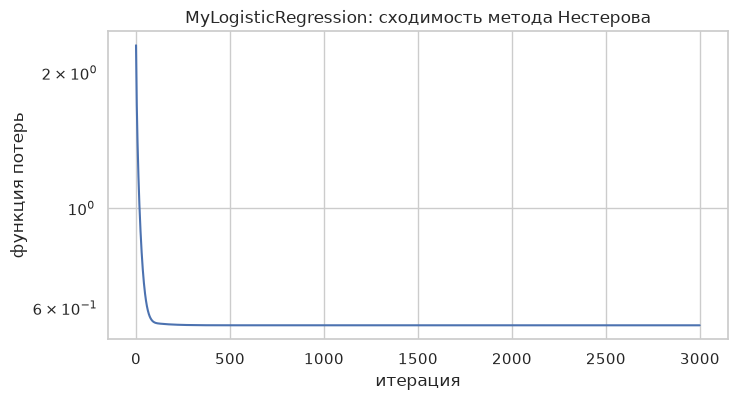

In [24]:
plt.figure(figsize=(8, 4))
plt.plot(my_clf.loss_history_)
plt.yscale("log"); plt.xlabel("итерация"); plt.ylabel("функция потерь"); plt.title("MyLogisticRegression: сходимость метода Нестерова")
plt.show()

**Выводы.** С техниками улучшенного бейзлайна собственные реализации воспроизводят метрики sklearn в обеих задачах. Для линейной регрессии это ожидаемо: решение аналитическое. Для логистической регрессии метод Нестерова за 3000 итераций подходит к минимуму достаточно близко, чтобы предсказания совпали. На графике видно, что функция потерь монотонно убывает и выходит на плато. По времени своя логистическая регрессия заметно медленнее L-BFGS: методу первого порядка нужны тысячи итераций там, где квазиньютоновскому методу хватает сотен. Итоговое качество определяется предобработкой и признаками, а не реализацией алгоритма.

## 5. Итоги

Итоговые таблицы и сохранение результатов ЛР2

In [25]:
res_c, res_r = pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T
path = save_results("lab2_linear", results)
print("Результаты сохранены в", path.relative_to(ROOT))
display(res_c.style.highlight_max(color="lightgreen").format("{:.4f}"))
display(res_r.style.highlight_min(subset=["MAE", "RMSE"], color="lightgreen").highlight_max(subset=["R2"], color="lightgreen").format("{:.4f}"))

Результаты сохранены в results/lab2_linear.json


,accuracy,f1_macro
sklearn baseline,0.1768,0.1394
sklearn improved,0.6790,0.6763
custom baseline,0.2053,0.1771
custom improved,0.6790,0.6763


,MAE,RMSE,R2
sklearn baseline,6.8823,9.6147,0.2202
sklearn improved,6.3337,9.6997,0.2064
custom baseline,6.8823,9.6147,0.2202
custom improved,6.3337,9.6997,0.2064


Сравнение с ЛР1: улучшенные модели KNN и линейных моделей на тесте

In [26]:
lab1 = json.loads((RESULTS_DIR / "lab1_knn.json").read_text())
pd.DataFrame({
    "GTZAN macro-F1 ↑": {"KNN (ЛР1)": lab1["classification"]["sklearn improved"]["f1_macro"],
                         "Логистическая регрессия (ЛР2)": results["classification"]["sklearn improved"]["f1_macro"]},
    "MSD MAE ↓": {"KNN (ЛР1)": lab1["regression"]["sklearn improved"]["MAE"],
                  "Линейная регрессия (ЛР2)": results["regression"]["sklearn improved"]["MAE"]},
})

,GTZAN macro-F1 ↑,MSD MAE ↓
KNN (ЛР1),0.6828,7.0208
Логистическая регрессия (ЛР2),0.6763,NaN
Линейная регрессия (ЛР2),NaN,6.3337


### Выводы по лабораторной работе

1. **Бейзлайн.** Логистическая регрессия «из коробки» на сырых признаках GTZAN практически не работает: оптимизатор не сходится из-за разного масштаба признаков. Линейная регрессия, наоборот, уже в бейзлайне лучше улучшенного KNN из ЛР1: аналитическое решение не зависит от масштаба, а связь тембра с годом во многом линейна.
2. **Улучшение бейзлайна.** Для линейных моделей решает работа с признаками и целевой переменной:
   * стандартизация обязательна для итеративной оптимизации;
   * квантильное преобразование признаков помогает в обеих задачах;
   * полиномиальные признаки с сильной L2-регуляризацией дают лучший результат в классификации;
   * сплайны по признакам и логарифмирование скошенного таргета дают лучший результат в регрессии;
   * Huber-потери помогают сами по себе, но не в сочетании с логарифмированием таргета (обе техники борются с хвостом старых записей);
   * подбор регуляризации важен только при большом числе признаков;
   * логарифмирование таргета снижает MAE ценой небольшого роста RMSE.
3. **Собственная реализация.** МНК через `lstsq` совпадает с sklearn точно. Логистическая регрессия с методом Нестерова сходится к тому же минимуму, что и L-BFGS. Эксперимент с градиентным спуском показал, почему масштабирование критично для итеративных методов: на сырых признаках число обусловленности огромно, и спуск не сходится.
4. **Сравнение с KNN.** В регрессии линейная модель заметно лучше KNN: MAE 6.33 против 7.02, и даже бейзлайн линейной регрессии лучше улучшенного KNN. Связь тембра с годом в основном глобальная и монотонная, и сплайны описывают её лучше, чем локальное усреднение соседей в 90-мерном пространстве. В классификации модели примерно равны: логистическая регрессия лучше на кросс-валидации (0.713 против 0.702), KNN — на тесте (0.683 против 0.676). Различие в пределах погрешности оценки на 200 тестовых треках.